In [1]:
# Import Standard Packages
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py
import seaborn as sns
import sys
from os import environ


In [2]:
%load_ext autoreload
%autoreload 2
    
# Find Paths for and Import NeuroPy and Eraser
# Needs to be set for each PC
if environ["HOME"] == "/Users/kimqi":
    neuropy_path = Path('/home/kimqi/Documents/Repositories/NeuroPy')
    eraser_path = Path('/home/kimqi/Documents/Repositories/Eraser')
elif environ["HOME"] == "/home/nkinsky":
    neuropy_path = Path('/data/GitHub/NeuroPy')
    eraser_path = Path('/data/GitHub/Eraser')
sys.path.append(str(neuropy_path))
sys.path.append(str(eraser_path))

# Import NeuroPy Packages
from neuropy.utils.ccg import correlograms
from neuropy.utils.mathutil import contiguous_regions
from neuropy.io.openephysio import get_dat_timestamps
from neuropy.plotting import Fig
from neuropy.io.binarysignalio import BinarysignalIO
from neuropy.plotting.signals import plot_signal_traces
from neuropy.utils.signal_process import filter_sig
from neuropy.analyses import oscillations
from neuropy.plotting import spikes


# Import Eraser Packages
from Ephys.ephys import *

/home/nkinsky/miniforge3/envs/NeuroPy/lib/python3.11/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.5.5.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [3]:
# Set Data and Figure Directories
# Needs to be set for each PC
if environ["HOME"] == "/Users/kimqi":
    fig_save_dir = Path('/home/kimqi/Documents/Code/Pencil/Plots')
    working_dir = Path('/media/kimqi/BK/Data/Anisomycin/Recording_Rats/Creampuff')
elif environ["HOME"] == "/home/nkinsky":
    fig_save_dir = Path('/data3/Anisomycin/Recording_Rats/Creampuff')
    working_dir = Path('/data3/Anisomycin/Recording_Rats/Creampuff')
# # Set working_dir in ephys module.
# set_working_dir(working_dir)

# # Check so functions that depend on working_dir will still work
# check_for_working_dir()

In [4]:
FigS5 = Fig(4, 5, num="Figure S5", size=(7, 3), fontsize=6)
print(FigS5.fig.get_size_inches())

[7. 3.]


<Figure size 700x300 with 0 Axes>

In [5]:
saline1_folder = '2024_07_15_Saline1'
ani_folder = '2024_07_17_Anisomycin'
saline2_folder = '2024_07_18_Saline2'

folder_list = [saline1_folder, ani_folder, saline2_folder]
unit_type = ['single', 'single', 'single']
session = ['saline1', 'ANI', 'saline2']

In [6]:
saline2_timestamps = get_dat_timestamps(working_dir / saline2_folder)

start time = 2024-07-18 10:44:06.254000-04:00
start time = 2024-07-18 10:56:53.545000-04:00
start time = 2024-07-18 11:16:12.276000-04:00
start time = 2024-07-18 11:45:02.927000-04:00
start time = 2024-07-18 12:11:35.142000-04:00
start time = 2024-07-18 12:23:21.989000-04:00
start time = 2024-07-18 12:26:48.689000-04:00
start time = 2024-07-18 12:58:21.460000-04:00
start time = 2024-07-18 13:11:19.839000-04:00
start time = 2024-07-18 13:41:56.327000-04:00
start time = 2024-07-18 14:02:49.439000-04:00
start time = 2024-07-18 14:31:14.667000-04:00
start time = 2024-07-18 14:53:21.537000-04:00
start time = 2024-07-18 14:58:30.226000-04:00


In [7]:
load_events_csv(saline2_folder, saline2_timestamps.iloc[0], working_dir=working_dir)

,start,stop,label
0,2024-07-18 10:44:00-04:00,2024-07-18 11:14:50-04:00,Pre
1,2024-07-18 11:15:00-04:00,2024-07-18 11:15:10-04:00,Injection
2,2024-07-18 11:16:00-04:00,2024-07-18 12:25:00-04:00,Post
3,2024-07-18 12:26:00-04:00,2024-07-18 12:57:50-04:00,Track 1
4,2024-07-18 12:58:00-04:00,2024-07-18 14:30:50-04:00,Post 2
5,2024-07-18 14:31:00-04:00,2024-07-18 14:58:32-04:00,Track 2


In [8]:
corr_by_epoch_saline2, time_bins_saline2, epochs_used_saline2 = calc_ccg_by_epoch(saline2_folder, timestamps=saline2_timestamps, working_dir=working_dir)

Calculating CCGs for epoch Pre
Calculating CCGs for epoch Injection
Calculating CCGs for epoch Post
Calculating CCGs for epoch Track 1
Calculating CCGs for epoch Post 2
Calculating CCGs for epoch Track 2


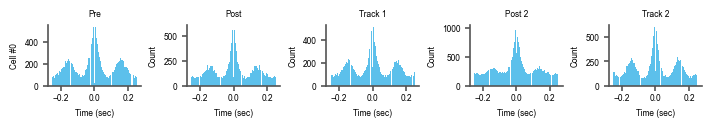

In [9]:
# Plot ACGs
ax_saline2 = []
for i in range(5):
    ax_saline2.append(FigS5.subplot(FigS5.gs[0, i]))
ax_saline2 = np.array(ax_saline2)[None, :]
plot_ccg_by_epoch(corr_by_epoch_saline2[:, 10, 10, :].reshape((corr_by_epoch_saline2.shape[0], 1, 1, corr_by_epoch_saline2.shape[3])), time_bins_saline2, epochs_used_saline2, 'Saline2 combined',
                                    ax=ax_saline2)

FigS5.fig

### Import eeg file and get raw theta and SWR traces

In [10]:
# Find EEG file and get Theta/SWR signals
sorted((working_dir / saline2_folder).glob("*.eeg"))[0]
saline2_signal = BinarysignalIO(sorted((working_dir / saline2_folder).glob("*.eeg"))[0], n_channels=35, sampling_rate=1250)
print(saline2_signal)

duration: 15363.86 seconds 
duration: 4.27 hours 



In [11]:
saline2_epochs = load_events_csv(saline2_folder, start_time=saline2_timestamps.iloc[0], working_dir=working_dir)
saline2_epochs

,start,stop,label
0,2024-07-18 10:44:00-04:00,2024-07-18 11:14:50-04:00,Pre
1,2024-07-18 11:15:00-04:00,2024-07-18 11:15:10-04:00,Injection
2,2024-07-18 11:16:00-04:00,2024-07-18 12:25:00-04:00,Post
3,2024-07-18 12:26:00-04:00,2024-07-18 12:57:50-04:00,Track 1
4,2024-07-18 12:58:00-04:00,2024-07-18 14:30:50-04:00,Post 2
5,2024-07-18 14:31:00-04:00,2024-07-18 14:58:32-04:00,Track 2


Pre
t_start:  [0.]
t_stop:  [1719.7056]


(-2.044117647058824, 2.3558823529411765)

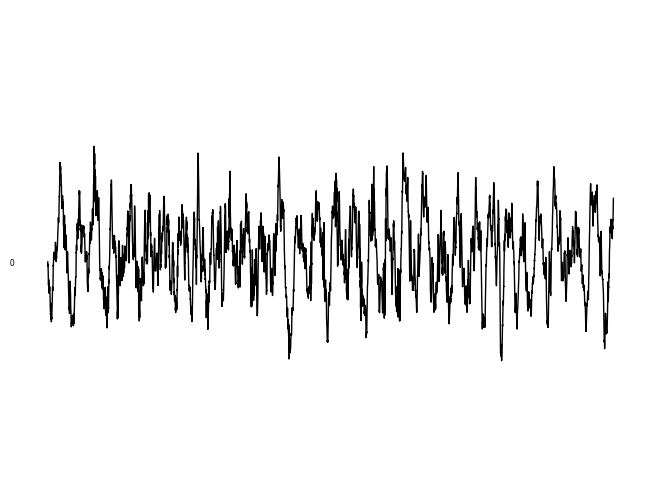

In [12]:
def get_epoch_signal(signal, epoch, epochs_df, channel_indx=None, SR=30000):
    SR = 30000
    epochs = epochs_df

    print(epoch)
    ts = saline2_timestamps.squeeze()
    epoch_use = epochs[epochs['label'] == epoch]
    # start_sec = ts.searchsorted(epoch_use['start'].dt.tz_localize(ts.iloc[0].tz))/SR
    start_sec = ts.searchsorted(epoch_use['start'])/SR
    print('t_start: ', start_sec)
    # stop_sec = ts.searchsorted(epoch_use['stop'].dt.tz_localize(ts.iloc[0].tz))/SR
    stop_sec = ts.searchsorted(epoch_use['stop'])/SR
    print('t_stop: ', stop_sec)
    # start_sec = ts.searchsorted(epoch_use['start'])/SR
    # stop_sec = ts.searchsorted(epoch_use['stop'])/SR

    return signal.get_signal(channel_indx=channel_indx, t_start=start_sec, t_stop=stop_sec)

# Make sure it is working well by plotting
pre_theta = get_epoch_signal(saline2_signal, 'Pre', saline2_epochs, channel_indx=4)
ax = plot_signal_traces(pre_theta.time_slice(t_start=750, t_stop=755))
ax.set_ylim(np.array(ax.get_ylim())*2)

In [13]:
ax_theta = FigS5.subplot2grid(FigS5.gs[1:, 0:2], grid=(3, 1), return_axes=True)

### TODO: set ylim to be all the same
track_theta = get_epoch_signal(saline2_signal, 'Track 1', saline2_epochs, channel_indx=4)
post_theta = get_epoch_signal(saline2_signal, 'Post', saline2_epochs, channel_indx=4)
post_hp = filter_sig.highpass(post_theta, cutoff=2)  # highpass filter to get rid of floating ground issue in homecage
track2_theta = get_epoch_signal(saline2_signal, 'Track 2', saline2_epochs, channel_indx=4)

Track 1
t_start:  [5672.08886667]
t_stop:  [7565.72486667]
Post
t_start:  [1719.7056]
t_stop:  [5612.08886667]
Track 2
t_start:  [12920.75026667]
t_stop:  [14426.42186667]


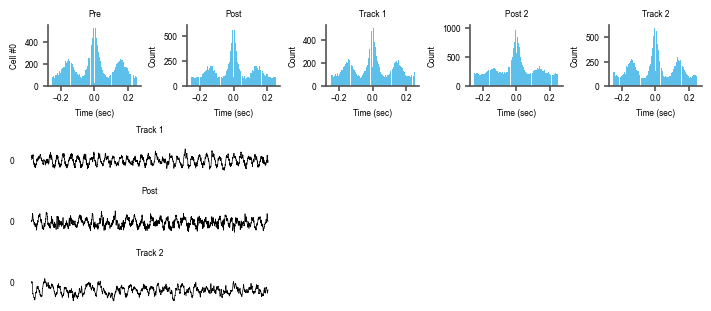

In [14]:
# Track Post Saline2
plot_signal_traces(track_theta.time_slice(t_start=5805, t_stop=5810), ax=ax_theta[0], lw=0.5)
ax_theta[0].set_title('Track 1')

# Post 
plot_signal_traces(post_theta.time_slice(t_start=1722, t_stop=1727), ax=ax_theta[1], lw=0.5)
ax_theta[1].set_title('Post')
ax_theta[1].sharey(ax_theta[0])

# Track 2 Post Saline 2
plot_signal_traces(track2_theta.time_slice(t_start= 12992, t_stop=12997), ax=ax_theta[2], lw=0.5)
ax_theta[2].set_title('Track 2')
ax_theta[2].sharey(ax_theta[0])

ax_theta[2].set_ylim(np.array(ax_theta[2].get_ylim())*1.6)
FigS5.fig


In [15]:
from neuropy.core.session import ProcessData

# basepath = '/media/kimqi/BK/Data/Anisomycin/Recording_Rats/Creampuff/2024_07_18_Saline2'
basepath = working_dir / saline2_folder
sess = ProcessData(basepath)

No dat file found, not loading


In [16]:
from neuropy.io.phyio import PhyIO
from neuropy.core.neurons import Neurons
phy_dir = sorted(sess.basepath.glob("**/params.py"))[0].parent
sess.phy = PhyIO(dirname=phy_dir)

sess.neurons = Neurons(sess.phy.spiketrains, t_stop=sess.eegfile.duration, neuron_ids=sess.phy.neuron_ids,
                       neuron_type=sess.phy.cluster_info["group"], waveforms=sess.phy.waveforms, 
                       waveforms_amplitude=sess.phy.waveforms_amplitude, sampling_rate=sess.recinfo.dat_sampling_rate,
                       peak_channels=sess.phy.peak_channels, shank_ids=sess.phy.shank_ids)

# 
for sh in np.unique(sess.neurons.shank_ids.astype(int)):
    sess.recinfo.write_neurons(sess.neurons.neuron_slice(np.where(sess.neurons.shank_ids == sh)[0]), suffix_num=sh)

id column does not exist in cluster_info.tsv. Using cluster_id column instead.


In [17]:
sess.neurons

Neurons
 n_neurons: 12
 t_start: 0.0
 t_stop: 15363.8608
 neuron_type: ['good']

# Get Spikes/Probe Group, Not Necessary after running once

In [18]:
from neuropy.analyses.spkepochs import detect_pbe_epochs
bin_size=0.01
thresh = (2.5, None)
edge_cutoff = 0.5
duration = (0.1, None)
distance = None

# Collect MUA
sess.mua = sess.neurons.get_mua(bin_size=bin_size)

In [19]:
# Detect PBEs
sess.pbe = detect_pbe_epochs(sess.mua, thresh=thresh, edge_cutoff=edge_cutoff, duration=duration, distance=distance)
pbe_epochs_file = sess.filePrefix.with_suffix(".pbe_epochs.npy")
sess.pbe.save(pbe_epochs_file)
sess.recinfo.write_epochs(sess.pbe, ext='pbe')

2111 epochs reamining with durations within (0.1,None)
/data3/Anisomycin/Recording_Rats/Creampuff/2024_07_18_Saline2/Creampuff_Saline2.pbe_epochs.npy saved


In [20]:
# from neuropy.core.session import ProcessData
# import os

# def sess_use(basepath=os.getcwd()):
#     return ProcessData(basepath)

# # sess = sess_use('/media/kimqi/BK/Data/Anisomycin/Recording_Rats/Creampuff/2024_07_18_Saline2')
# sess = sess_use(basepath)
# print(sess.recinfo)

# signal = sess.eegfile.get_signal()

/data3/Anisomycin/Recording_Rats/Creampuff/2024_07_18_Saline2/Creampuff_Saline2.probegroup.npy saved


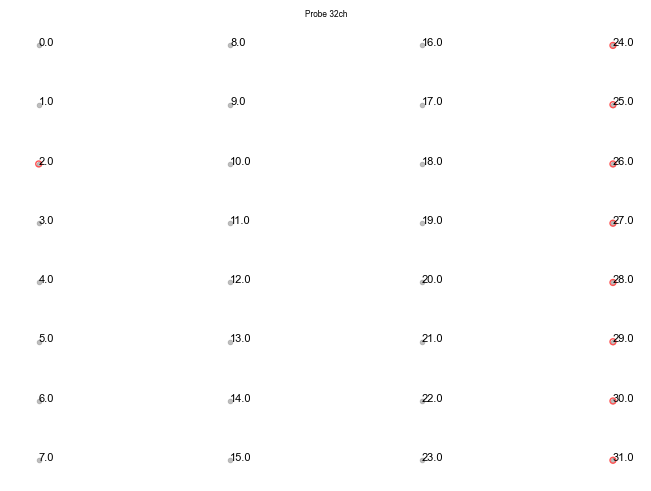

In [21]:
from neuropy.core import Shank, Probe, ProbeGroup
from neuropy.plotting import plot_probe
shank = Shank()
shank = shank.auto_generate(columns=4, contacts_per_column=8, xpitch=125,
                   ypitch=-20, channel_id=np.arange(0, 32, 1))
shank.set_disconnected_channels(sess.recinfo.skipped_channels)
probe = Probe(shank)
prbgrp = ProbeGroup()
prbgrp.add_probe(probe)
plot_probe(prbgrp)
prbgrp.filename = sess.filePrefix.with_suffix(".probegroup.npy")
prbgrp.save(prbgrp.filename)
sess.prbgrp = prbgrp

In [22]:
art_epochs_file = sess.filePrefix.with_suffix(".art_epochs.npy")
art_epochs = Epoch(epochs=None, file=art_epochs_file)

In [23]:
# Detect Ripple Epochs
signal = sess.eegfile.get_signal()
ripple_epochs = oscillations.detect_ripple_epochs(signal, sess.prbgrp, thresh=(2.5,5), ignore_epochs=art_epochs, ripple_channel=17)

Selected channels for ripples: [17]
716 epochs remaining with durations within (0.05,0.45)


In [24]:
ripple_epochs_file = sess.filePrefix.with_suffix(".ripple_epochs.npy")
sess.recinfo.write_epochs(epochs=ripple_epochs, ext='swr')
ripple_epochs.save(ripple_epochs_file)

/data3/Anisomycin/Recording_Rats/Creampuff/2024_07_18_Saline2/Creampuff_Saline2.ripple_epochs.npy saved


## Now grab some ripples

Track 1
t_start:  [5672.08886667]
t_stop:  [7565.72486667]


[]

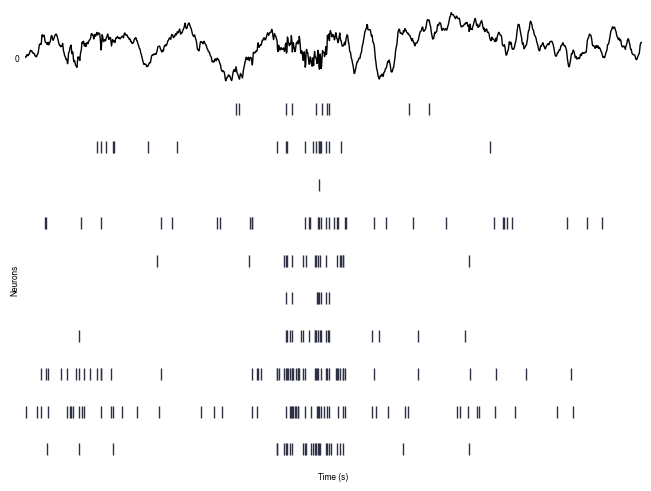

In [25]:
fig, ax = plt.subplots(2, 1, height_ratios=[1, 5], sharex=True)

swr_track = get_epoch_signal(saline2_signal, 'Track 1', saline2_epochs, channel_indx=[16])
swr_ax = plot_signal_traces(swr_track.time_slice(t_start=6028.26, t_stop=6029.26), ax=ax[0])

spikes.plot_raster(sess.neurons.time_slice(t_start=6028.26, t_stop=6029.26), ax=ax[1], markersize=8)
sns.despine(ax=ax[1], bottom=True, left=True)
ax[1].set_xticks([])

ax[1].set_yticks([])

Track 1
t_start:  [5672.08886667]
t_stop:  [7565.72486667]
Post
t_start:  [1719.7056]
t_stop:  [5612.08886667]
Track 2
t_start:  [12920.75026667]
t_stop:  [14426.42186667]


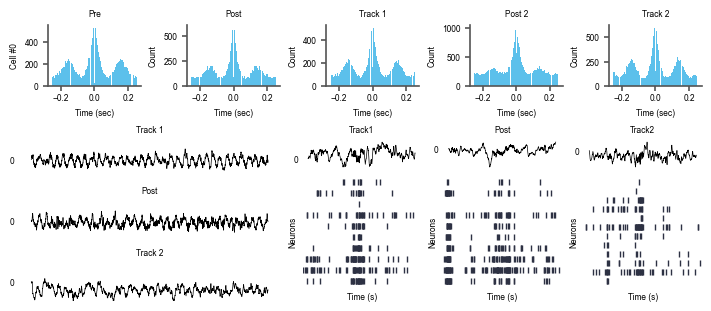

In [26]:
# Get Signals for various epochs to look for ripples
swr_track = get_epoch_signal(saline2_signal, 'Track 1', saline2_epochs, channel_indx=[16])
swr_post = get_epoch_signal(saline2_signal, 'Post', saline2_epochs, channel_indx=[16])
swr_track2 = get_epoch_signal(saline2_signal, 'Track 2', saline2_epochs, channel_indx=[16])

ax_swr = FigS5.subplot2grid(FigS5.gs[1:, 2:], height_ratios=[1, 4], grid=(2, 3), return_axes=True)

# Plot Track 1 LFP and Spikes
plot_signal_traces(swr_track.time_slice(t_start=6028.26, t_stop=6029.26), ax=ax_swr[0,0], lw=0.5)
spikes.plot_raster(sess.neurons.time_slice(t_start=6028.26, t_stop=6029.26), ax=ax_swr[1,0], markersize=4)
sns.despine(ax=ax_swr[1,0], bottom=True, left=True)
ax_swr[1,0].set_xticks([])
ax_swr[1,0].set_yticks([])
ax_swr[0,0].set_title('Track1')

# Plot Post LFP and Spikes
plot_signal_traces(swr_post.time_slice(t_start=2126.12, t_stop=2127.12), ax=ax_swr[0,1], lw=0.5)
spikes.plot_raster(sess.neurons.time_slice(t_start=2126.12, t_stop=2127.12), ax=ax_swr[1,1], markersize=4)
sns.despine(ax=ax_swr[1,1], bottom=True, left=True)
ax_swr[1,1].set_xticks([])
ax_swr[1,1].set_yticks([])
ax_swr[0,1].set_title('Post')

# Plot Track 2 LFP and Spikes
# Plot Post LFP and Spikes
plot_signal_traces(swr_track2.time_slice(t_start=12973.98, t_stop=12974.98), ax=ax_swr[0,2], lw=0.5)
spikes.plot_raster(sess.neurons.time_slice(t_start=12973.98, t_stop=12974.98), ax=ax_swr[1,2], markersize=4)
sns.despine(ax=ax_swr[1,2], bottom=True, left=True)
ax_swr[1,2].set_xticks([])
ax_swr[1,2].set_yticks([])
ax_swr[0,2].set_title('Track2')


FigS5.fig

In [27]:
FigS5.savefig(fig_save_dir / 'Figure S5.pdf')